# GVH Diagonal Cubic — Hierarchical Quadrupole & Internal-Frequency Gate (FAST)

**Mission :** éprouver la proposition « des sous-cubes peuvent être remplacés par un cube effectif qui conserve une signature de leurs mouvements internes ». On compare un **monopole** (cube sans détails) à un **monopole enrichi du quadrupôle** (cube portant une mémoire interne de la configuration Terre–Lune).

**Ce qui n'est PAS revendiqué :** nouvelle force GVH, loi inter-échelles démontrée, lien quantique/gravitatoire, calibration SI autonome, identité de fréquences micro/macro, prédiction GVH nouvelle.

**Architecture obligatoire :** 1. GVH → 2. Physique établie → 3. Test numérique minimal → 4. Verdict scientifique.

**Provenance :** notebook complémentaire au benchmark exécuté précédent (`GVH_Hierarchical_Cube_Frequency_Minimal_Benchmark_EXECUTED.ipynb`, SHA-256 indiqué dans les métadonnées et imprimé dans le notebook). Préserve les verrous `.3.3.27.3/.3.3.27.4`. Ne remplace pas les audits canoniques.

**Entrées indépendantes, sans réglage :** JPL DE440 : GM Terre = 398600.435507 km³/s², GM Lune = 4902.800118 km³/s². NASA : distance de référence 384400 km, période sidérale 27.3217 jours.

Sources : [JPL Astrodynamic Parameters](https://ssd.jpl.nasa.gov/astro_par.html), [NASA Moon Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/moonfact.html).

**Simplifications :** points matériels sphériques, séparation et vitesse angulaire constantes, trajectoire circulaire prescrite, observateur immobile sur l'axe x du repère barycentrique. Absence du Soleil et de la dynamique de marée. Les chiffres sont des témoins de méthode et ne représentent pas les éphémérides réelles.

# Niveau 1 — GVH : hypothèse hiérarchique, sans EOM

Deux sous-cubes Terre et Lune sont agrégés en un cube effectif à une échelle d'observation R. Nous proposons de garder, selon la précision voulue :

- **Monopole** : paramètre gravitationnel total \(\mu=\mu_E+\mu_M\), barycentre \(\mathbf X_{\rm CM}\) ;
- **Quadrupôle temporel** : \(Q\sim\mu_{\rm red}d^2\), orientation \(\hat{\mathbf u}(t)\), avec \(\mu_{\rm red}=\mu_E\mu_M/(\mu_E+\mu_M)\) ;
- **Fréquence interne mémorisée** : \(f=1/T\) et \(\hat{\mathbf u}(t)=(\cos 2\pi ft,\sin2\pi ft,0)\).

Le niveau « cube » est un **choix de résolution** : il ne prouve pas l'existence de cubes physiques fondamentaux. Ni l'action \(S_{\rm cand}\) ni une loi de couplage inter-cubes **GVH** ne sont dérivées dans ce benchmark.

**Question falsifiable interne au benchmark :** une fois les constantes physiques fixées, le quadrupôle newtonien réduit-il, sur une distance tenue à l'écart du test principal, l'erreur de l'approximation « cube effectif » ? La fréquence de la composante quadrupolaire dominante est-elle \(2f\) sans imposer cette fréquence au signal calculé ?

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import sympy as sp

# Paramètres externes : aucuns ajustements sur les sorties.
MU_E = 398600.435507 * 1e9       # m^3/s^2, JPL
MU_M = 4902.800118 * 1e9         # m^3/s^2, JPL
D = 384400e3                      # m, valeur moyenne de référence NASA
PERIOD_DAYS = 27.3217            # d, NASA ; INPUT, non prédiction
DAY_S = 86400.0
MU_TOT = MU_E + MU_M
MU_RED = MU_E * MU_M / MU_TOT
F_INPUT_HZ = 1.0 / (PERIOD_DAYS * DAY_S)

# Les distances sont fixées pour évaluer la qualité de la réduction, sans fit.
N = 2048
R_PRIMARY = 1e10                 # m : distance d'étude principale
R_HOLDOUT = 2e10                 # m : contrôle indépendant de la distance principale
R_RANGE = (1e9, R_PRIMARY, R_HOLDOUT, 1e11)

PREVIOUS = Path('/mnt/data/GVH_Hierarchical_Cube_Frequency_Minimal_Benchmark_EXECUTED.ipynb')
if PREVIOUS.exists():
    print('UPSTREAM_SHA256 =', hashlib.sha256(PREVIOUS.read_bytes()).hexdigest())
else:
    print('UPSTREAM_SHA256 unavailable: previous file not mounted')
print('F_INPUT_HZ =', f'{F_INPUT_HZ:.12g}')
print('F_QUAD_PREDICTED_HZ =', f'{2*F_INPUT_HZ:.12g}')
print('MU_RED [m^3/s^2] =', f'{MU_RED:.12g}')


UPSTREAM_SHA256 = 4b7230bb557b951abe6547a62dc428aeccc78e6d84cddb2506810ca94c78f5b5
F_INPUT_HZ = 4.23622032087e-07
F_QUAD_PREDICTED_HZ = 8.47244064174e-07
MU_RED [m^3/s^2] = 4.8432282314e+12


# Niveau 2 — Physique établie : expansion multipolaire newtonienne

Le champ exact, dans le modèle à deux masses ponctuelles, est :

\[
\mathbf a_{\rm exact}(\mathbf r,t)=\sum_{i\in\{E,M\}}
\mu_i\frac{\mathbf x_i(t)-\mathbf r}{|\mathbf r-\mathbf x_i(t)|^3}.
\]

Le champ du monopole barycentrique est \(\mathbf a_0=-\mu_{\rm tot}\mathbf r/R^3\). Pour \(R\gg d\), le premier terme omis est le quadrupôle. Dans ce modèle circulaire :

\[
\Phi_Q(\mathbf r,t)=-\frac{\mu_{\rm red}d^2}{2R^3}
\left[3(\hat{\mathbf r}\cdot\hat{\mathbf u}(t))^2-1\right].
\]

Au point \(\mathbf r=(R,0,0)\), le **champ radial** de la correction s'écrit :

\[
a_{Q,x}(t)=-\frac{3\mu_{\rm red}d^2}{4R^4}
\left[1+3\cos(2\Omega t)\right],\quad \Omega=2\pi f.
\]

La composante \(2f\) découle de l'identité \(\cos^2\theta=(1+\cos2\theta)/2\) et de l'expansion newtonienne ; ce n'est **pas** une onde gravitationnelle rayonnée ni une fréquence GVH dérivée. Le champ exact peut comporter des harmoniques supplémentaires venant des multipôles d'ordre supérieur.

**Limite de validité** : cette expansion est asymptotique pour \(d/R\ll1\), et ses erreurs doivent être quantifiées, particulièrement à proximité du couple.

In [2]:
# Vérification symbolique INDEPENDANTE du code de calcul du champ exact.
A, R, th = sp.symbols('A R theta', positive=True, real=True)
ax_q_from_gradient = A/(2*R**4) * (3 - 9*sp.cos(th)**2)
ax_q_harmonic = -3*A/(4*R**4)*(1 + 3*sp.cos(2*th))
G_SYMBOLIC_HARMONIC_PASS = bool(sp.trigsimp(ax_q_from_gradient - ax_q_harmonic) == 0)
assert G_SYMBOLIC_HARMONIC_PASS

# Le signal possède une moyenne non nulle et une modulation à 2*Omega.
q_mean_analytic = -3*MU_RED*D**2 / (4*R_PRIMARY**4)
q_harmonic_amplitude = 9*MU_RED*D**2 / (4*R_PRIMARY**4)
print('G_SYMBOLIC_HARMONIC_PASS =', G_SYMBOLIC_HARMONIC_PASS)
print('Quadrupole radial mean [m/s^2] =', q_mean_analytic)
print('Quadrupole radial harmonic amplitude [m/s^2] =', q_harmonic_amplitude)


G_SYMBOLIC_HARMONIC_PASS = True
Quadrupole radial mean [m/s^2] = -5.36738757538431e-11
Quadrupole radial harmonic amplitude [m/s^2] = 1.6102162726152927e-10


# Niveau 3 — Test numérique minimal

**Sans ajustement de paramètres :** calculer le champ exact, l'approximation monopolaire et l'approximation monopole + quadrupôle, en parcourant 2048 phases uniformes. Examiner :

1. erreur vectorielle maximale relative \(\max_\theta|\mathbf a_{\rm modèle}-\mathbf a_{\rm exact}|/|\mathbf a_0|\) ;
2. gain de précision sur le point principal R=10 millions km ;
3. robustesse à R=20 millions km **tenu à l'écart** ;
4. transformée de Fourier de la correction radiale exacte : position du pic dominant et proximité avec l'amplitude quadrupolaire analytique.

Les critères numériques ci-dessous ne testent que des identités/approximations **newtoniennes** et ne sont pas une validation GVH.

In [3]:
THETA = 2*np.pi*np.arange(N)/N
U = np.column_stack((np.cos(THETA), np.sin(THETA), np.zeros(N)))
X_E = -D*MU_M/MU_TOT*U
X_M = +D*MU_E/MU_TOT*U

# Identité barycentrique, calculée avant toute approche multipolaire.
G_BARYCENTER_PASS = bool(np.max(np.linalg.norm(MU_E*X_E+MU_M*X_M, axis=1))/(MU_TOT*D)<1e-14)
assert G_BARYCENTER_PASS

def fields_at_R(Rm):
    r = np.broadcast_to(np.array([Rm, 0., 0.]), U.shape)
    a_e = MU_E*(X_E-r)/np.linalg.norm(X_E-r,axis=1)[:,None]**3
    a_m = MU_M*(X_M-r)/np.linalg.norm(X_M-r,axis=1)[:,None]**3
    exact = a_e + a_m
    mono = np.broadcast_to(np.array([-MU_TOT/Rm**2,0.,0.]), exact.shape)
    s = np.sum(r*U, axis=1)
    # a_Q = -grad(Phi_Q) ; dérivée vectorielle d'une fonction du point de mesure r.
    quad = (MU_RED*D**2/2)*(6*s[:,None]*U/Rm**5
           -15*s[:,None]**2*r/Rm**7 + 3*r/Rm**5)
    return exact, mono, mono+quad, quad

rows=[]
for Rm in R_RANGE:
    exact,mono,enriched,quad=fields_at_R(Rm)
    a0_norm = MU_TOT/Rm**2
    mono_err = np.linalg.norm(exact-mono,axis=1)/a0_norm
    quad_err = np.linalg.norm(exact-enriched,axis=1)/a0_norm
    rows.append({'R_m':float(Rm), 'd_over_R':float(D/Rm),
        'monopole_max_error_pct':float(100*mono_err.max()),
        'monopole_quad_max_error_pct':float(100*quad_err.max()),
        'improvement_factor':float(mono_err.max()/quad_err.max())})
comparison = pd.DataFrame(rows)
print('G_BARYCENTER_PASS =',G_BARYCENTER_PASS)
print(comparison.to_string(index=False,float_format=lambda x:f'{x:.9g}'))
assert bool((comparison.monopole_quad_max_error_pct<comparison.monopole_max_error_pct).all())


G_BARYCENTER_PASS = True
  R_m  d_over_R  monopole_max_error_pct  monopole_quad_max_error_pct  improvement_factor
1e+09    0.3844              1.02674381                  0.494665041          2.07563446
1e+10   0.03844           0.00560010265               0.000279315009          20.0494155
2e+10   0.01922           0.00136426491                3.4068003e-05          40.0453445
1e+11  0.003844          5.34752264e-05               2.67349928e-07          200.019603


In [4]:
# FFT : la fréquence est LUE dans les données calculées, pas injectée dans la FFT.
exact, mono, enriched, quad = fields_at_R(R_PRIMARY)
signal = exact[:,0] - mono[:,0]
signal_centered = signal - signal.mean()
amplitudes = 2*np.abs(np.fft.rfft(signal_centered))/N
k_dominant = int(np.argmax(amplitudes[1:N//4]) + 1)
f_detected = k_dominant*F_INPUT_HZ
predicted_amp = 9*MU_RED*D**2/(4*R_PRIMARY**4)
freq_amp_rel_gap = abs(amplitudes[2]-predicted_amp)/predicted_amp

G_DOMINANT_HARMONIC_PASS = (k_dominant==2)
G_Q_AMPLITUDE_CONSISTENCY_PASS = bool(freq_amp_rel_gap<0.02) # QA illustrative, pas GVH
G_ENRICHED_BETTER_PRIMARY_PASS = bool(comparison.loc[1,'improvement_factor']>10.)
G_ENRICHED_BETTER_HOLDOUT_PASS = bool(comparison.loc[2,'improvement_factor']>10.)
assert all([G_DOMINANT_HARMONIC_PASS, G_Q_AMPLITUDE_CONSISTENCY_PASS,
            G_ENRICHED_BETTER_PRIMARY_PASS, G_ENRICHED_BETTER_HOLDOUT_PASS])
print('Dominant FFT index k =',k_dominant)
print('Detected peak frequency =',f_detected,'Hz')
print('Analytic quadrupole frequency =',2*F_INPUT_HZ,'Hz')
print('Analytic quadrupole amplitude =',predicted_amp,'m/s^2')
print('Exact radial correction k=2 amplitude =',amplitudes[2],'m/s^2')
print('Relative amplitude gap =',freq_amp_rel_gap)


Dominant FFT index k = 2
Detected peak frequency = 8.472440641741966e-07 Hz
Analytic quadrupole frequency = 8.472440641741966e-07 Hz
Analytic quadrupole amplitude = 1.6102162726152927e-10 m/s^2
Exact radial correction k=2 amplitude = 1.6118111866968772e-10 m/s^2
Relative amplitude gap = 0.0009904968100924694


## Test de dépendance à l'échelle et représentation spectrale

Le rapport \(d/R\) est choisi par la géométrie de mesure, pas par une « constante GVH ». La correction quadrupolaire décroit plus rapidement avec R que le monopole. L'amélioration doit donc être plus nette loin du système. Le graphe montre des **erreurs d'approximation newtonienne**, pas de signature d'une loi GVH.

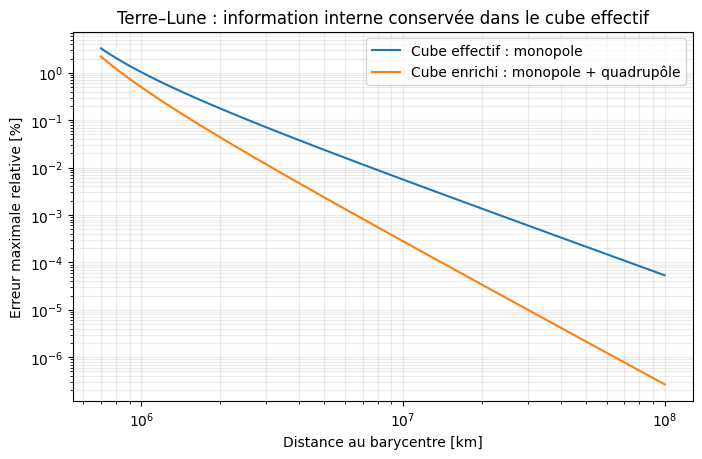

In [5]:
import matplotlib.pyplot as plt
rs = np.geomspace(7e8, 1e11, 100)
mono_errors, quad_errors=[],[]
for rr in rs:
    ae, am, aq, _ = fields_at_R(rr)
    mono_errors.append(100*np.max(np.linalg.norm(ae-am,axis=1))/(MU_TOT/rr**2))
    quad_errors.append(100*np.max(np.linalg.norm(ae-aq,axis=1))/(MU_TOT/rr**2))
fig, ax=plt.subplots(figsize=(8,4.8))
ax.loglog(rs/1e3, mono_errors, label='Cube effectif : monopole')
ax.loglog(rs/1e3, quad_errors, label='Cube enrichi : monopole + quadrupôle')
ax.set(xlabel='Distance au barycentre [km]', ylabel='Erreur maximale relative [%]',
       title='Terre–Lune : information interne conservée dans le cube effectif')
ax.grid(True,which='both',alpha=.25)
ax.legend()
plt.show()


# Niveau 4 — Verdict scientifique et porte GVH

**Acquis dans le benchmark newtonien** :

- Sous un mouvement circulaire **prescrit** et une distance fixe, l'agrégation barycentrique est exacte au niveau du monopole.
- L'agrégation enrichie par le quadrupôle représente mieux le champ extérieur à distance suffisante, sans ajustement de paramètre.
- Le mouvement interne laisse une modulation détectable à \(2f\) dans la correction quadrupolaire du champ radial observé.
- Ce résultat relève **entièrement de la physique gravitationnelle établie**.

**Verrous scientifiques conservés** :

- Pas d'EOM GVH dérivée et résolue **pour ce couplage inter-cubes** dans ce notebook.
- Pas de coefficient de correction GVH libre fixé à la main ; aucune échelle \(L_*\), \(T_*\) ajustée à une sortie.
- Pas de liaison physique GVH démontrée entre fréquence Terre–Lune et fréquence atomique.
- Aucun résultat expérimental nouveau ni aucune supériorité de GVH démontrée.

**Prochaine porte autorisée :** extraire d'une action candidate GVH une équation/règle de couplage concret pour deux cubes, réduire à la limite faible ou comparer la prédiction à ce benchmark newtonien. Si aucune loi n'est dérivée, verdict `BLOCKED_GVH_DISCRIMINANT`, et non `PASS_NEW_PHYSICS`.

In [6]:
checks = {
  'symbolic_harmonic': G_SYMBOLIC_HARMONIC_PASS,
  'barycenter_identity': G_BARYCENTER_PASS,
  'quadrupole_improves_all_tested_distances': bool((comparison.monopole_quad_max_error_pct<comparison.monopole_max_error_pct).all()),
  'dominant_harmonic_index_2': G_DOMINANT_HARMONIC_PASS,
  'harmonic_amplitude_QA_pass': G_Q_AMPLITUDE_CONSISTENCY_PASS,
  'primary_quadrupole_improvement_pass': G_ENRICHED_BETTER_PRIMARY_PASS,
  'distance_holdout_improvement_pass': G_ENRICHED_BETTER_HOLDOUT_PASS,
}
NEWTONIAN_BENCHMARK_PASS=all(checks.values())
GVH_INTERCUBE_EOM_DERIVED_IN_THIS_NOTEBOOK=False
GVH_INDEPENDENT_SI_SCALE_DERIVED_IN_THIS_NOTEBOOK=False
GVH_MICRO_MACRO_RESONANCE_DERIVED_IN_THIS_NOTEBOOK=False
GVH_NEW_PHYSICS_VALIDATED=False
SCIENTIFIC_VERDICT='NEWTONIAN_BENCHMARK_PASS__GVH_DISCRIMINANT_BLOCKED'
assert NEWTONIAN_BENCHMARK_PASS
assert not GVH_INTERCUBE_EOM_DERIVED_IN_THIS_NOTEBOOK
assert not GVH_NEW_PHYSICS_VALIDATED
result={
  'notebook': 'GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST',
  'canonical_status':'COMPLEMENTARY_NOT_CANONICAL',
  'upstream_file_sha256':hashlib.sha256(PREVIOUS.read_bytes()).hexdigest() if PREVIOUS.exists() else None,
  'four_levels': {
    'level1_GVH':'HIERARCHY_PROPOSED__INTERCUBE_EOM_NOT_DERIVED_HERE',
    'level2_established_physics':'NEWTONIAN_MULTIPOLE_QUADRUPOLE_BENCHMARK',
    'level3_numeric':'FAR_FIELD_APPROXIMATION_AND_2F_SPECTRAL_WITNESS',
    'level4_scientific_verdict':SCIENTIFIC_VERDICT,
  },
  'constants':{'GM_E_m3s2':MU_E,'GM_M_m3s2':MU_M,'distance_m':D,
               'T_moon_reference_days':PERIOD_DAYS},
  'results':{'checks':checks, 'distance_table':comparison.to_dict('records'),
    'f_internal_Hz':F_INPUT_HZ, 'f_quadrupole_predicted_Hz':2*F_INPUT_HZ,
    'f_fft_peak_Hz':f_detected,'fft_harmonic_index':k_dominant,
    'quadrupole_amplitude_analytic_ms2':predicted_amp,
    'FFT_k2_amplitude_exact_ms2':float(amplitudes[2]),
    'FFT_amp_relative_gap':float(freq_amp_rel_gap)},
  'locks':{'GVH_intercube_EOM_derived':False,'GVH_SI_scale_derived':False,
    'GVH_micro_macro_coupling_derived':False,'new_GVH_physics_validated':False},
  'pass':NEWTONIAN_BENCHMARK_PASS,
  'next_authorized':'DERIVE_GVH_INTERCUBE_COUPLING_FROM_S_CAND_AND_COMPARE'
}
export=Path('/mnt/data/GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_results.json')
export.write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
print('SCIENTIFIC_VERDICT =',SCIENTIFIC_VERDICT)
print('NEWTONIAN_BENCHMARK_PASS =',NEWTONIAN_BENCHMARK_PASS)
print('GVH_NEW_PHYSICS_VALIDATED =',GVH_NEW_PHYSICS_VALIDATED)
print('Result JSON =',export)


SCIENTIFIC_VERDICT = NEWTONIAN_BENCHMARK_PASS__GVH_DISCRIMINANT_BLOCKED
NEWTONIAN_BENCHMARK_PASS = True
GVH_NEW_PHYSICS_VALIDATED = False
Result JSON = /mnt/data/GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_results.json
